In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.sparse import vstack
from sklearn.datasets import load_svmlight_file
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

In [5]:
from pathlib import Path

DATA_DIR = Path.cwd()

print("Current folder:", DATA_DIR)
print("DAT files found:", list(DATA_DIR.glob("*.dat")))

Current folder: C:\Users\Surya
DAT files found: [WindowsPath('C:/Users/Surya/batch1.dat'), WindowsPath('C:/Users/Surya/batch10.dat'), WindowsPath('C:/Users/Surya/batch2.dat'), WindowsPath('C:/Users/Surya/batch3.dat'), WindowsPath('C:/Users/Surya/batch4.dat'), WindowsPath('C:/Users/Surya/batch5.dat'), WindowsPath('C:/Users/Surya/batch6.dat'), WindowsPath('C:/Users/Surya/batch7.dat'), WindowsPath('C:/Users/Surya/batch8.dat'), WindowsPath('C:/Users/Surya/batch9.dat'), WindowsPath('C:/Users/Surya/NTUSER.DAT')]


In [6]:
batch_files = [
    DATA_DIR / f"batch{i}.dat"
    for i in range(1, 11)
]

print("All 10 batches found:", all(f.exists() for f in batch_files))

All 10 batches found: True


In [9]:
from pathlib import Path

from sklearn.datasets import load_svmlight_file

DATA_DIR = Path(r"C:\Users\Surya")

for i in range(1, 11):
    file = DATA_DIR / f"batch{i}.dat"
    print(file.name, file.exists())

batch1.dat True
batch2.dat True
batch3.dat True
batch4.dat True
batch5.dat True
batch6.dat True
batch7.dat True
batch8.dat True
batch9.dat True
batch10.dat True


In [12]:
file_path = r"C:\Users\Surya\batch1.dat"

with open(file_path, "r", encoding="utf-8", errors="replace") as f:
    for i in range(5):
        print(repr(f.readline()))

'1;10.000000 1:15596.162100 2:1.868245 3:2.371604 4:2.803678 5:7.512213 6:-2.739388 7:-3.344671 8:-4.847512 9:15326.691400 10:1.768526 11:2.269085 12:2.713374 13:6.915721 14:-2.488324 15:-3.082212 16:-5.056975 17:2789.383100 18:2.754759 19:0.430440 20:0.649457 21:1.795029 22:-0.426662 23:-0.584313 24:-1.438976 25:2581.568600 26:2.680623 27:0.399746 28:0.605065 29:1.786704 30:-0.400115 31:-0.550743 32:-1.728611 33:685.399400 34:1.682904 35:0.122736 36:0.223703 37:0.584691 38:-0.138196 39:-0.236907 40:-0.781959 41:797.773800 42:1.742488 43:0.152483 44:0.218904 45:0.841862 46:-0.164646 47:-0.315720 48:-0.791447 49:3128.848900 50:3.605537 51:0.532422 52:0.763062 53:2.118983 54:-0.557197 55:-0.809953 56:-2.344130 57:3136.877800 58:3.555169 59:0.535883 60:0.761388 61:1.499244 62:-0.571480 63:-0.944425 64:-2.658358 65:13540.673800 66:1.765738 67:2.006883 68:2.519022 69:6.261430 70:-2.172101 71:-2.694967 72:-3.791499 73:13831.753900 74:1.746493 75:2.057165 76:2.391239 77:5.695234 78:-2.350776 

In [14]:
from pathlib import Path
import numpy as np

DATA_DIR = Path(r"C:\Users\Surya")

batch_files = [
    DATA_DIR / f"batch{i}.dat"
    for i in range(1, 11)
]

def read_batch(file_path):
    features = []
    labels = []

    with open(file_path, "r", encoding="utf-8") as f:
        for line_no, line in enumerate(f, start=1):
            line = line.strip()

            if not line:
                continue

            parts = line.split(None, 1)

            if len(parts) != 2:
                raise ValueError(
                    f"Unexpected format in {file_path.name}, line {line_no}: {line[:100]}"
                )

            label_text, feature_text = parts[0], parts[1]

            # Some files separate label and features with a semicolon
            if ";" in label_text:
                label_text, extra = label_text.split(";", 1)
                feature_text = extra + " " + feature_text

            labels.append(float(label_text))

            row = np.zeros(128, dtype=float)

            for item in feature_text.split():
                if ":" not in item:
                    continue

                index, value = item.split(":", 1)
                index = int(index)

                # SVMlight feature indices are normally 1-based
                if 1 <= index <= 128:
                    row[index - 1] = float(value)

            features.append(row)

    return np.array(features), np.array(labels)


all_X = []
all_y = []

for file in batch_files:
    X_batch, y_batch = read_batch(file)
    all_X.append(X_batch)
    all_y.append(y_batch)

X = np.vstack(all_X)
y = np.concatenate(all_y)

print("Dataset loaded successfully!")
print("Features shape:", X.shape)
print("Labels shape:", y.shape)

Dataset loaded successfully!
Features shape: (13910, 128)
Labels shape: (13910,)


Number of samples: 13910
Number of features: 128
Missing values: 0
Infinite values: 0
Number of original classes: 6


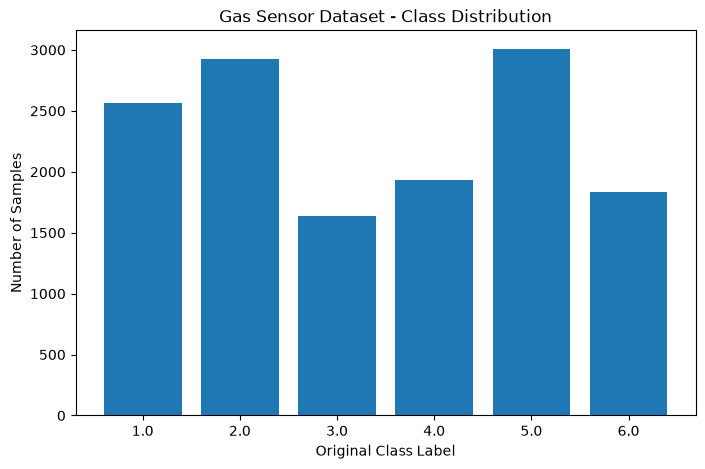

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Missing values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())
print("Number of original classes:", len(np.unique(y)))

# Original class distribution
class_counts = pd.Series(y).value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.xlabel("Original Class Label")
plt.ylabel("Number of Samples")
plt.title("Gas Sensor Dataset - Class Distribution")
plt.show()

In [16]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Replace infinite values with NaN
X_temp = X.copy()
X_temp[~np.isfinite(X_temp)] = np.nan

# Fill missing values
imputer = SimpleImputer(strategy="mean")
X_clean = imputer.fit_transform(X_temp)

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)

print("Preprocessing completed!")
print("Scaled dataset shape:", X_scaled.shape)

Preprocessing completed!
Scaled dataset shape: (13910, 128)


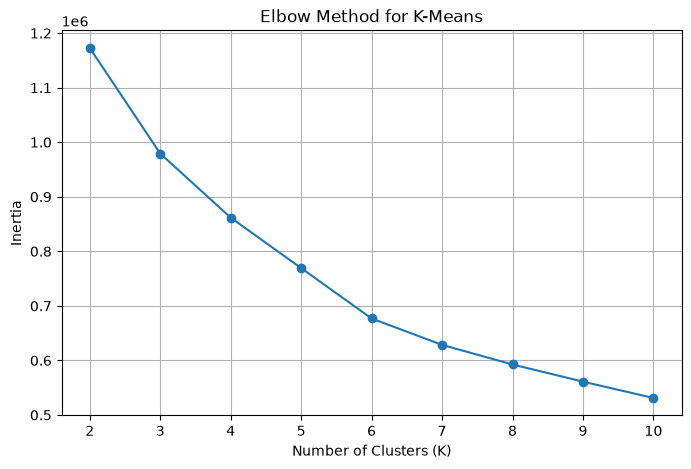

In [17]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia_values = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [18]:
from sklearn.cluster import KMeans
import pandas as pd
import numpy as np

kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

results_df = pd.DataFrame(X_scaled)
results_df["Cluster"] = clusters
results_df["Original_Label"] = y

print("K-Means training completed!")

K-Means training completed!


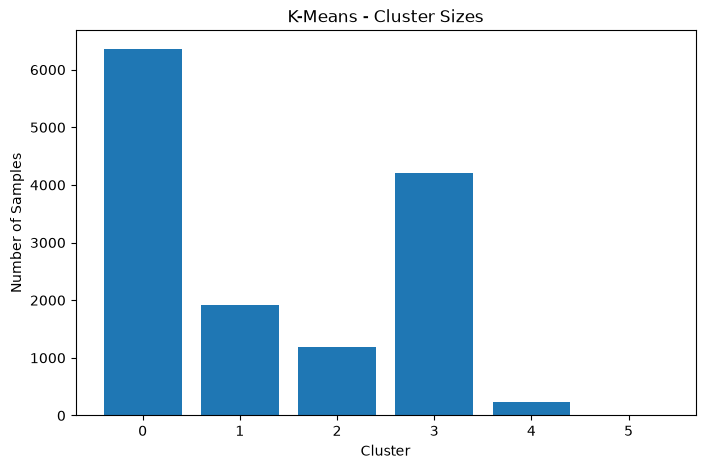

In [19]:
cluster_counts = pd.Series(clusters).value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(cluster_counts.index.astype(str), cluster_counts.values)
plt.xlabel("Cluster")
plt.ylabel("Number of Samples")
plt.title("K-Means - Cluster Sizes")
plt.show()

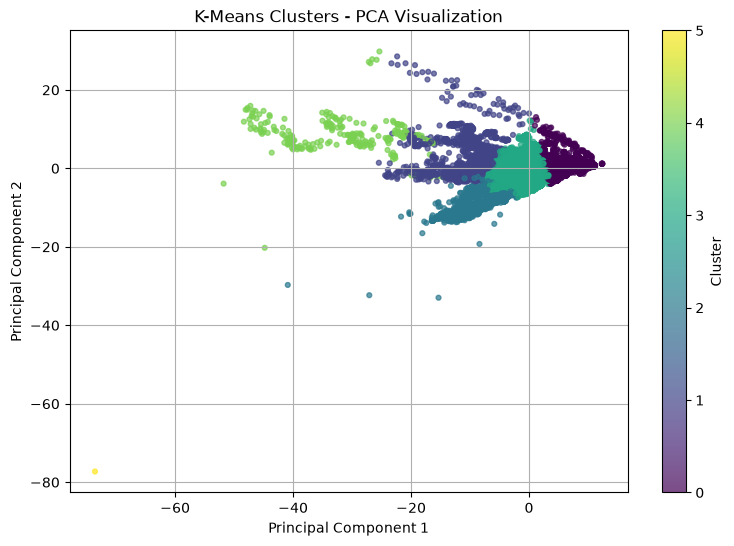

Variance retained by 2 components: 68.56 %


In [20]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    s=12,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters - PCA Visualization")
plt.colorbar(scatter, label="Cluster")
plt.grid(True)
plt.show()

print(
    "Variance retained by 2 components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [21]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

silhouette = silhouette_score(X_scaled, clusters)
db_score = davies_bouldin_score(X_scaled, clusters)
ch_score = calinski_harabasz_score(X_scaled, clusters)

metrics_df = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Score",
        "Calinski-Harabasz Score"
    ],
    "Value": [
        silhouette,
        db_score,
        ch_score
    ]
})

display(metrics_df)

,Metric,Value
0,Silhouette Score,0.325492
1,Davies-Bouldin Score,0.989512
2,Calinski-Harabasz Score,4534.196573


In [22]:
# Save each sample's cluster assignment
results_df.to_csv("gas_sensor_kmeans_results.csv", index=False)

# Save evaluation metrics
metrics_df.to_csv("gas_sensor_kmeans_metrics.csv", index=False)

# Save cluster sizes
cluster_counts = pd.Series(clusters).value_counts().sort_index()

cluster_sizes_df = pd.DataFrame({
    "Cluster": cluster_counts.index,
    "Number_of_Samples": cluster_counts.values
})

cluster_sizes_df.to_csv("gas_sensor_cluster_sizes.csv", index=False)

print("All results saved successfully!")

All results saved successfully!


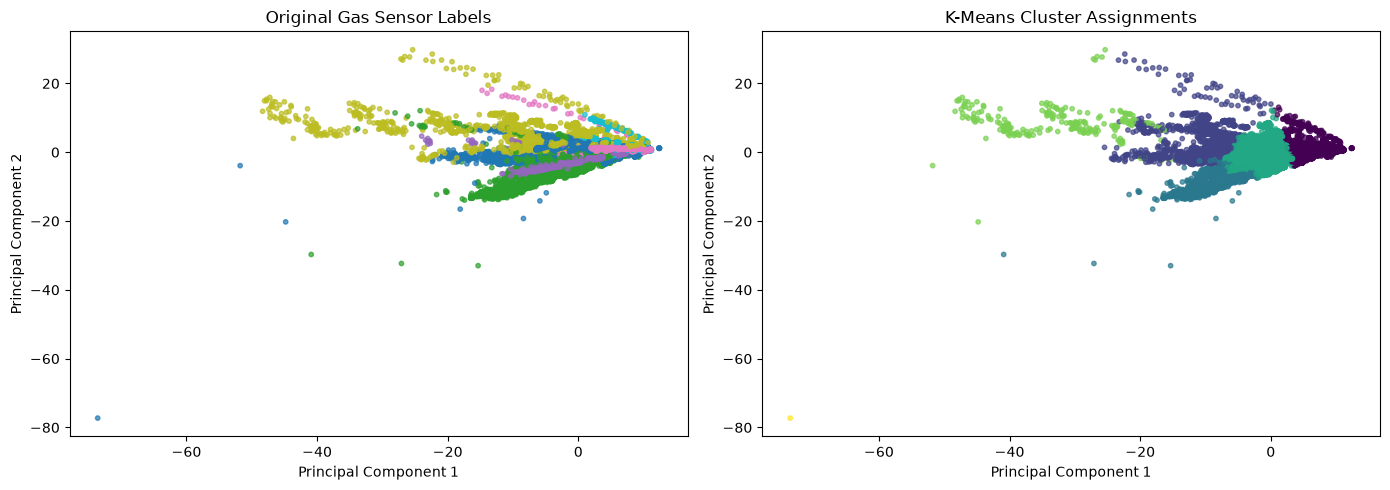

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=y, cmap="tab10", s=10, alpha=0.7
)
axes[0].set_title("Original Gas Sensor Labels")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

axes[1].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=clusters, cmap="viridis", s=10, alpha=0.7
)
axes[1].set_title("K-Means Cluster Assignments")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

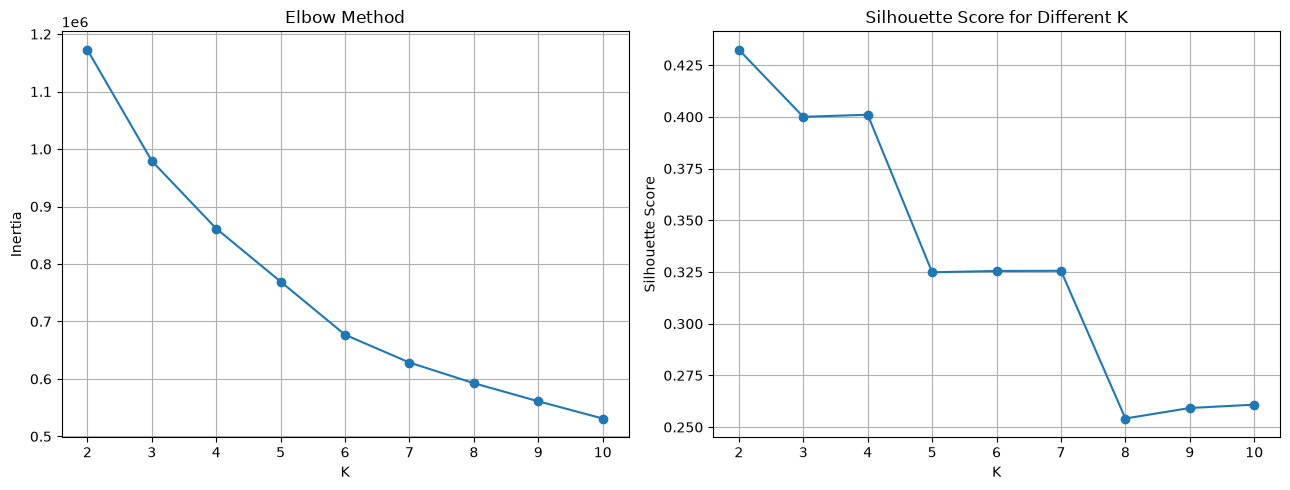

In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

k_values = range(2, 11)
inertia_values = []
silhouette_values = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(X_scaled, labels)
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(list(k_values), inertia_values, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inertia")
axes[0].grid(True)

axes[1].plot(list(k_values), silhouette_values, marker="o")
axes[1].set_title("Silhouette Score for Different K")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(True)

plt.tight_layout()
plt.show()

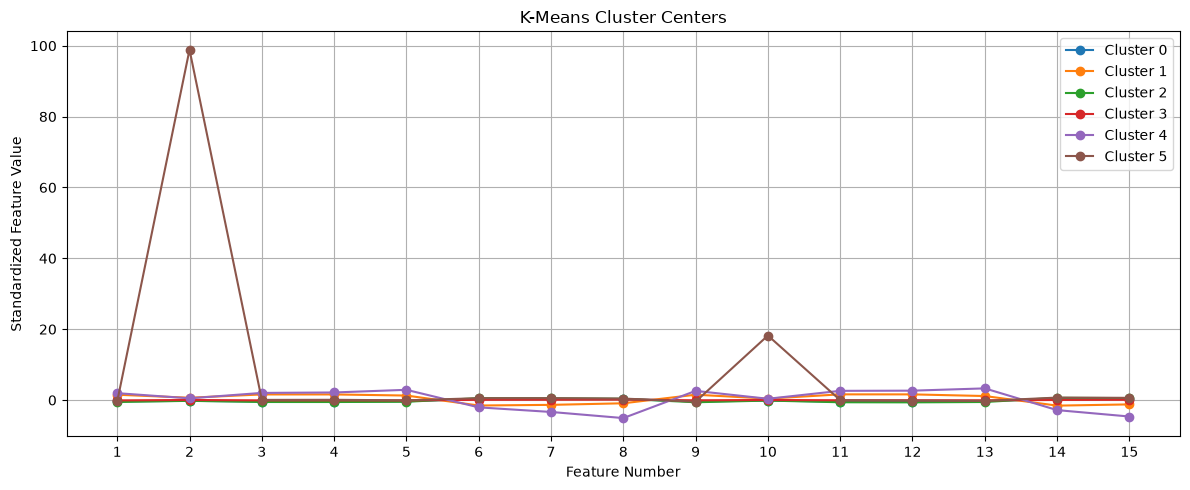

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Get cluster centers
centers = kmeans.cluster_centers_

# Plot cluster centers across the first 15 features
plt.figure(figsize=(12, 5))

for i in range(centers.shape[0]):
    plt.plot(range(1, 16), centers[i, :15], marker='o',
             label=f'Cluster {i}')

plt.title("K-Means Cluster Centers")
plt.xlabel("Feature Number")
plt.ylabel("Standardized Feature Value")
plt.xticks(range(1, 16))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

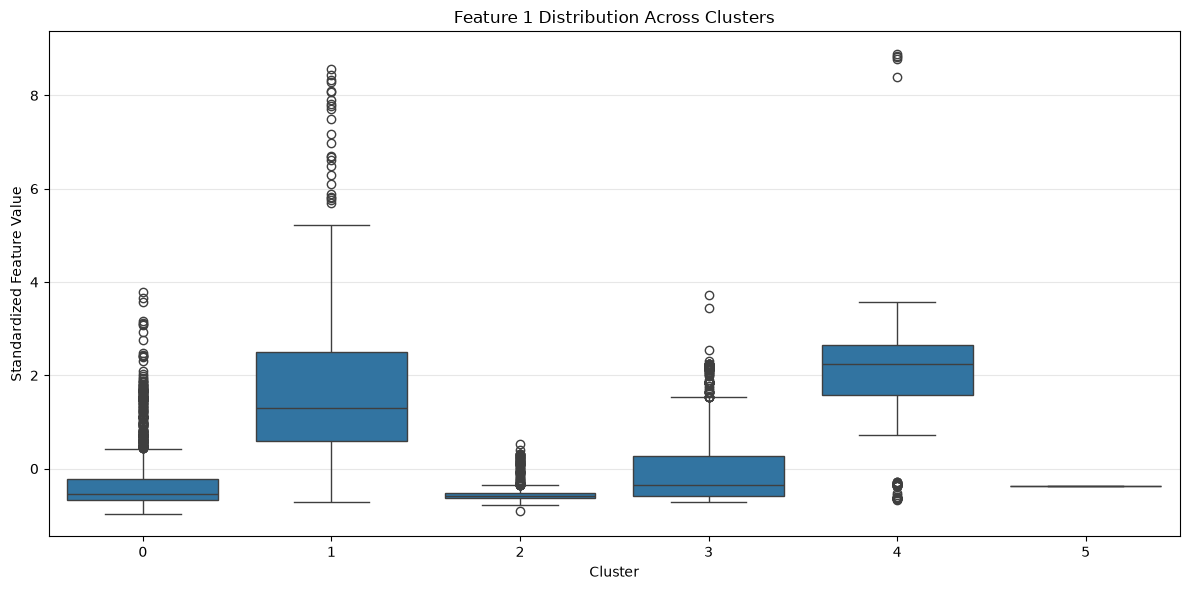

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

cluster_data = pd.DataFrame(X_scaled[:, :5],
                            columns=[f'Feature {i}' for i in range(1, 6)])

cluster_data["Cluster"] = clusters

plt.figure(figsize=(12, 6))

sns.boxplot(data=cluster_data, x="Cluster", y="Feature 1")

plt.title("Feature 1 Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Standardized Feature Value")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
import joblib

joblib.dump(kmeans, "gas_sensor_kmeans_model.pkl")
joblib.dump(scaler, "gas_sensor_scaler.pkl")
joblib.dump(imputer, "gas_sensor_imputer.pkl")

print("Clustering model and preprocessing objects saved successfully!")

Clustering model and preprocessing objects saved successfully!


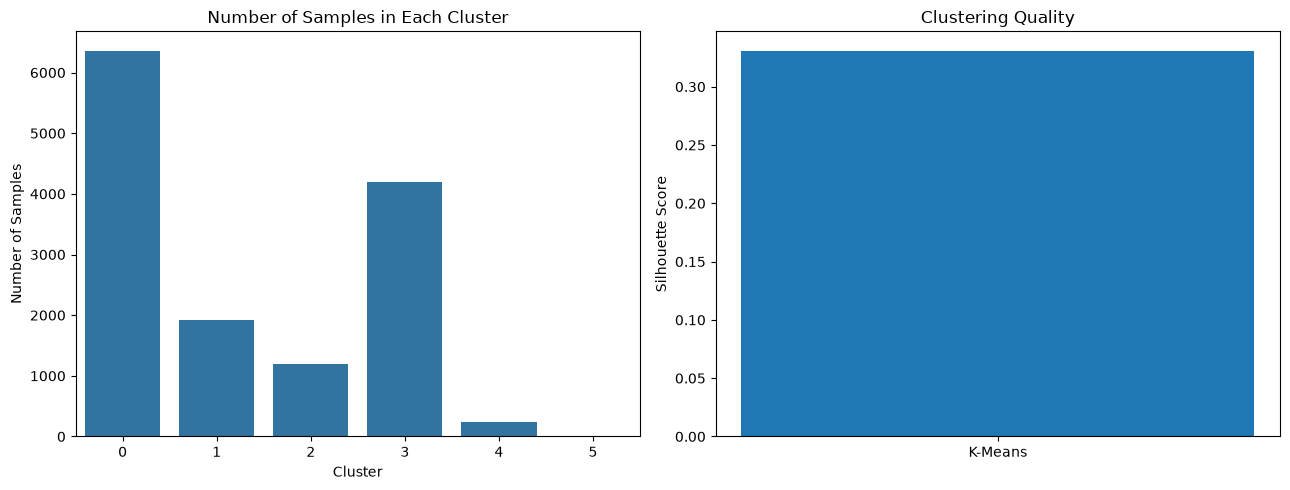

Number of clusters: 6
Silhouette Score (sample estimate): 0.3309


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Cluster distribution
sns.countplot(x=clusters, ax=axes[0])
axes[0].set_title("Number of Samples in Each Cluster")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Number of Samples")

# Clustering quality
sil_score = silhouette_score(
    X_scaled, clusters, sample_size=5000, random_state=42
)

axes[1].bar(["K-Means"], [sil_score])
axes[1].set_title("Clustering Quality")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

print(f"Number of clusters: {len(set(clusters))}")
print(f"Silhouette Score (sample estimate): {sil_score:.4f}")